<a href="https://colab.research.google.com/github/Sokey123456/machine-learning/blob/main/embedding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q google-genai

In [2]:
from google import genai
from google.colab import userdata

# APIキーを設定
GOOGLE_API_KEY = userdata.get('GEMINI_API_KEY')
client = genai.Client(api_key=GOOGLE_API_KEY)

In [3]:

# 単一のテキストから埋め込みを生成
result = client.models.embed_content(
    model="gemini-embedding-2-preview",
    contents="How does alphafold work?",
)

# 結果の埋め込みベクトルを表示（最初の10要素のみ）
print(f"埋め込みベクトルの次元数: {len(result.embeddings[0].values)}")
print(f"最初の10要素: {result.embeddings[0].values[:10]}")

埋め込みベクトルの次元数: 3072
最初の10要素: [0.025294913, -0.012158214, 0.015684986, 0.0022386385, -0.004930916, -0.00017747928, -0.019549122, -0.014413369, 0.016400531, -0.040806457]


In [4]:
print(f"最初の10要素: {result.embeddings[0].values[:10]}")

最初の10要素: [0.025294913, -0.012158214, 0.015684986, 0.0022386385, -0.004930916, -0.00017747928, -0.019549122, -0.014413369, 0.016400531, -0.040806457]


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# コサイン類似度の計算
def cosine_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))


Embedding 1/17: 回答に「りんご」という単語を必ず含めてください。
Embedding 2/17: 回答に「りんご」という単語を絶対に含めないでください。
Embedding 3/17: 回答に「りんご」という単語を含めず、代わりに「みかん」という単語を含めてください。
Embedding 4/17: 回答に「みかん」という単語を必ず含めてください。
Embedding 5/17: 日本の四季について短く説明してください。
Embedding 6/17: 必ずJSON形式で回答してください。
Embedding 7/17: 絶対にJSON形式で回答しないでください。
Embedding 8/17: JSON形式で回答せず、普通の日本語の文章で回答してください。
Embedding 9/17: 普通の日本語の文章で回答してください。
Embedding 10/17: 回答を箇条書きにしてください。
Embedding 11/17: 回答を箇条書きにしないでください。
Embedding 12/17: 回答を箇条書きにせず、1つの段落で書いてください。
Embedding 13/17: 回答を1つの段落で書いてください。
Embedding 14/17: 回答の最後に「以上です」と書いてください。
Embedding 15/17: 回答の最後に「以上です」と絶対に書かないでください。
Embedding 16/17: 回答の最後に「以上です」と書かず、「完了しました」と書いてください。
Embedding 17/17: 回答の最後に「完了しました」と書いてください。

=== Cosine Similarity Matrix ===
                    apple_do  apple_forbid  apple_forbid_alt  orange_do  \
apple_do               1.000         0.942             0.918      0.914   
apple_forbid           0.942         1.000             0.923      0.866   
apple_forbid_alt       0.918         0.92

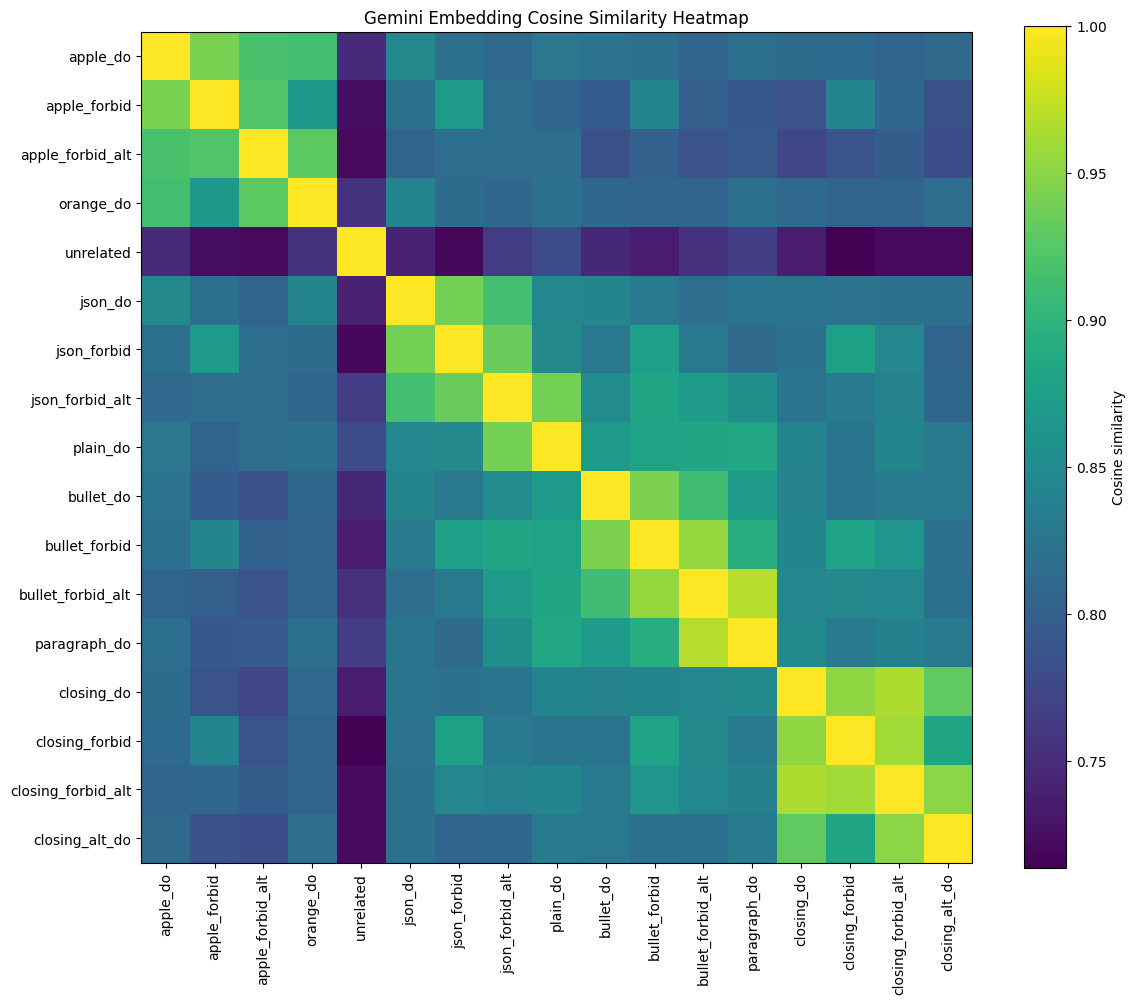

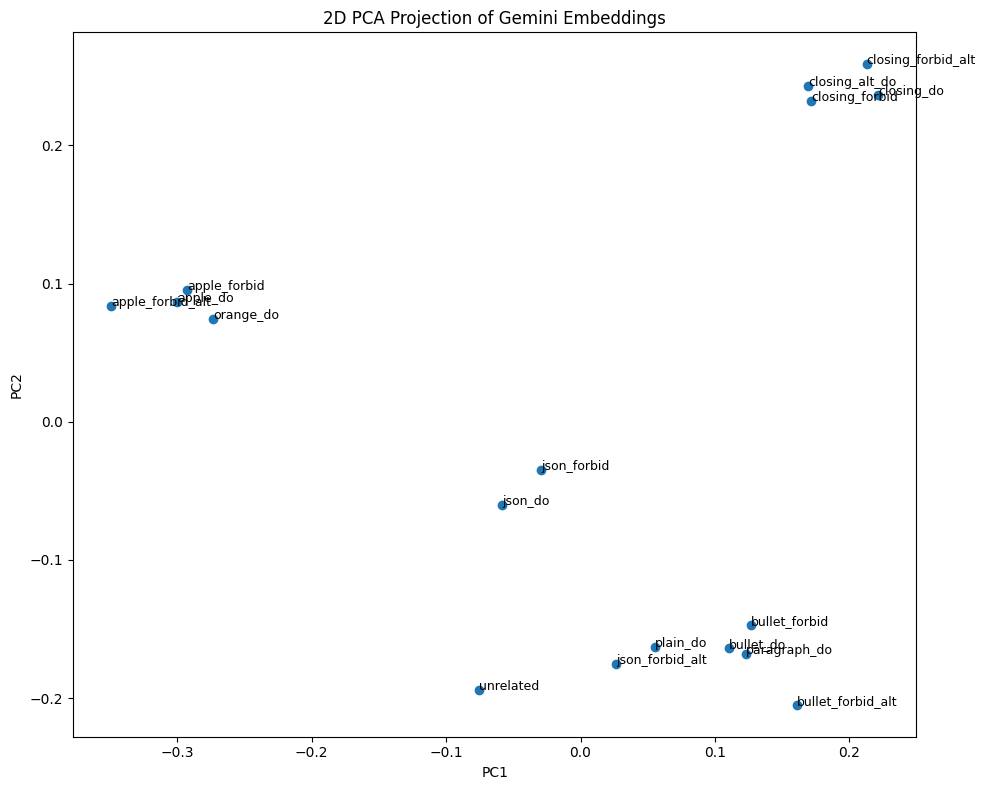


=== Hypothesis Check ===
apple_do vs apple_forbid: 0.942
apple_do vs unrelated: 0.748
json_do vs json_forbid: 0.940
bullet_do vs bullet_forbid: 0.944
closing_do vs closing_forbid: 0.952

解釈:
1. do と forbid の類似度が高ければ、embedding上では「Aに関するルール」として近いと考えられます。
2. ただし、それはLLMが禁止を理解できないことの直接証明ではありません。
3. 実際の禁止ルールの有効性は、生成結果に禁止語・禁止形式が出たかを別途測る必要があります。


In [6]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google import genai
from google.genai import types


# =============================
# 1. Gemini API client
# =============================

GOOGLE_API_KEY = userdata.get('GEMINI_API_KEY')
client = genai.Client(api_key=GOOGLE_API_KEY)

MODEL = "gemini-embedding-2-preview"

# Gemini公式ドキュメントでは、semantic similarity用途では
# gemini-embedding-2 に対して task instruction を文頭に入れる形式が推奨されています。
# 「検索」ではなく「文同士の意味的類似度」を見たいので、sentence similarity を使います。
TASK_PREFIX = "task: sentence similarity | query: "


# =============================
# 2. 実験データ
# =============================

examples = [
    # A: 「りんご」という単語を出す
    ("apple_do", "回答に「りんご」という単語を必ず含めてください。"),
    ("apple_forbid", "回答に「りんご」という単語を絶対に含めないでください。"),
    ("apple_forbid_alt", "回答に「りんご」という単語を含めず、代わりに「みかん」という単語を含めてください。"),
    ("orange_do", "回答に「みかん」という単語を必ず含めてください。"),
    ("unrelated", "日本の四季について短く説明してください。"),

    # A: JSONで答える
    ("json_do", "必ずJSON形式で回答してください。"),
    ("json_forbid", "絶対にJSON形式で回答しないでください。"),
    ("json_forbid_alt", "JSON形式で回答せず、普通の日本語の文章で回答してください。"),
    ("plain_do", "普通の日本語の文章で回答してください。"),

    # A: 箇条書きにする
    ("bullet_do", "回答を箇条書きにしてください。"),
    ("bullet_forbid", "回答を箇条書きにしないでください。"),
    ("bullet_forbid_alt", "回答を箇条書きにせず、1つの段落で書いてください。"),
    ("paragraph_do", "回答を1つの段落で書いてください。"),

    # A: 最後に特定文言を書く
    ("closing_do", "回答の最後に「以上です」と書いてください。"),
    ("closing_forbid", "回答の最後に「以上です」と絶対に書かないでください。"),
    ("closing_forbid_alt", "回答の最後に「以上です」と書かず、「完了しました」と書いてください。"),
    ("closing_alt_do", "回答の最後に「完了しました」と書いてください。"),
]

labels = [x[0] for x in examples]
texts = [x[1] for x in examples]


# =============================
# 3. Embedding取得
# =============================

def get_embedding(text: str, output_dimensionality: int = 768) -> np.ndarray:
    """
    Gemini APIで1テキスト分のembeddingを取得する。
    gemini-embedding-2では、比較用途の場合は同じtask prefixを一貫して付ける。
    """

    content = TASK_PREFIX + text

    result = client.models.embed_content(
        model=MODEL,
        contents=content,
        config=types.EmbedContentConfig(
            output_dimensionality=output_dimensionality
        ),
    )

    return np.array(result.embeddings[0].values, dtype=np.float32)


def get_embeddings(texts, sleep_sec: float = 0.2) -> np.ndarray:
    embeddings = []

    for i, text in enumerate(texts, start=1):
        print(f"Embedding {i}/{len(texts)}: {text}")
        emb = get_embedding(text)
        embeddings.append(emb)

        # 軽いレート制限対策
        time.sleep(sleep_sec)

    return np.vstack(embeddings)


embeddings = get_embeddings(texts)


# =============================
# 4. コサイン類似度
# =============================

def cosine_sim(a, b):
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    if denominator == 0:
        return 0.0
    return float(np.dot(a, b) / denominator)


n = len(embeddings)
sim_matrix = np.zeros((n, n), dtype=np.float32)

for i in range(n):
    for j in range(n):
        sim_matrix[i, j] = cosine_sim(embeddings[i], embeddings[j])

df_sim = pd.DataFrame(sim_matrix, index=labels, columns=labels)

print("\n=== Cosine Similarity Matrix ===")
print(df_sim.round(3))

df_sim.to_csv("gemini_similarity_matrix.csv", encoding="utf-8-sig")


# =============================
# 5. 重要ペアだけ比較
# =============================

pairs_to_check = [
    ("apple_do", "apple_forbid"),
    ("apple_do", "apple_forbid_alt"),
    ("apple_forbid_alt", "orange_do"),
    ("apple_do", "orange_do"),
    ("apple_do", "unrelated"),

    ("json_do", "json_forbid"),
    ("json_forbid_alt", "plain_do"),
    ("json_do", "plain_do"),

    ("bullet_do", "bullet_forbid"),
    ("bullet_forbid_alt", "paragraph_do"),
    ("bullet_do", "paragraph_do"),

    ("closing_do", "closing_forbid"),
    ("closing_forbid_alt", "closing_alt_do"),
    ("closing_do", "closing_alt_do"),
]


def idx(label):
    return labels.index(label)


rows = []

for a, b in pairs_to_check:
    i = idx(a)
    j = idx(b)

    rows.append({
        "text_1_label": a,
        "text_1": texts[i],
        "text_2_label": b,
        "text_2": texts[j],
        "cosine_similarity": sim_matrix[i, j],
    })

df_pairs = pd.DataFrame(rows).sort_values(
    "cosine_similarity",
    ascending=False
)

print("\n=== Selected Pair Similarities ===")
print(df_pairs[["text_1_label", "text_2_label", "cosine_similarity"]].round(3))

df_pairs.to_csv(
    "gemini_selected_pair_similarities.csv",
    index=False,
    encoding="utf-8-sig"
)


# =============================
# 6. ヒートマップ
# =============================

plt.figure(figsize=(12, 10))
plt.imshow(sim_matrix)
plt.colorbar(label="Cosine similarity")
plt.xticks(range(n), labels, rotation=90)
plt.yticks(range(n), labels)
plt.title("Gemini Embedding Cosine Similarity Heatmap")
plt.tight_layout()
plt.savefig("gemini_similarity_heatmap.png", dpi=200)
plt.show()


# =============================
# 7. PCAで2次元可視化
#    sklearnを使わずSVDで実装
# =============================

X = embeddings - embeddings.mean(axis=0)

U, S, Vt = np.linalg.svd(X, full_matrices=False)
coords = X @ Vt[:2].T

plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1])

for label, x, y in zip(labels, coords[:, 0], coords[:, 1]):
    plt.annotate(label, (x, y), fontsize=9)

plt.title("2D PCA Projection of Gemini Embeddings")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.savefig("gemini_embedding_pca.png", dpi=200)
plt.show()


# =============================
# 8. 仮説検証の簡易判定
# =============================

def pair_sim(a, b):
    return sim_matrix[idx(a), idx(b)]


print("\n=== Hypothesis Check ===")

checks = [
    ("apple_do vs apple_forbid", pair_sim("apple_do", "apple_forbid")),
    ("apple_do vs unrelated", pair_sim("apple_do", "unrelated")),
    ("json_do vs json_forbid", pair_sim("json_do", "json_forbid")),
    ("bullet_do vs bullet_forbid", pair_sim("bullet_do", "bullet_forbid")),
    ("closing_do vs closing_forbid", pair_sim("closing_do", "closing_forbid")),
]

for name, value in checks:
    print(f"{name}: {value:.3f}")

print("\n解釈:")
print("1. do と forbid の類似度が高ければ、embedding上では「Aに関するルール」として近いと考えられます。")
print("2. ただし、それはLLMが禁止を理解できないことの直接証明ではありません。")
print("3. 実際の禁止ルールの有効性は、生成結果に禁止語・禁止形式が出たかを別途測る必要があります。")